#  Cinema Audience Forecasting - Kaggle Competition

## Project Overview

This project focuses on predicting cinema audience counts for theater shows using historical booking data, theater characteristics, and temporal patterns. Accurate audience forecasting helps cinema operators optimize resource allocation, staff scheduling, and inventory management.

## Objective

Build a robust forecasting model that predicts daily audience count for each theater using:
- Historical attendance patterns
- Booking data (tickets booked/sold)
- Theater characteristics (type, area, location)
- Temporal features (day of week, date patterns)
- Recent trends and seasonality

## Dataset

**Data Sources:**
- `booknow_visits.csv` - Target variable (audience_count)
- `booknow_booking.csv` - BookNow platform booking records
- `cinePOS_booking.csv` - CinePOS platform booking records
- `booknow_theaters.csv` - Theater metadata (type, area, coordinates)
- `date_info.csv` - Date and day-of-week information
- `movie_theater_id_relation.csv` - ID mapping between platforms

**Key Features:**
- 826 theaters across multiple regions
- 214,000+ daily theater records
- Date range: Over one year of historical data
- Multiple data sources merged for comprehensive features

## Methodology

### 1. **Data Preprocessing**
   - Load and merge datasets from multiple sources
   - Handle missing values and duplicates
   - Convert datetime formats
   - Aggregate booking data by theater and date

### 2. **Exploratory Data Analysis (EDA)**
   - 12+ comprehensive visualizations
   - Distribution analysis of target variable
   - Weekly and monthly seasonality patterns
   - Theater performance comparison
   - Correlation analysis

### 3. **Feature Engineering**
   - Weekday averages per theater
   - 7-day rolling averages for trend capture
   - Theater-specific fallback predictions
   - Temporal features (day of week, month)

### 4. **Model Development**
   - **Statistical Models (4):**
     - Weekday + Trend blends (50/50, 70/30, 30/70)
     - Adaptive performance-weighted ensemble
   
   - **Machine Learning Models (4):**
     - Random Forest Regressor
     - Ridge Regression
     - XGBoost Regressor
     - LightGBM Regressor

### 5. **Hyperparameter Optimization**
   - RandomizedSearchCV on best-performing model
   - 3-fold cross-validation
   - Parallel processing (n_jobs=-1) for efficiency

### 6. **Model Selection & Evaluation**
   - Performance comparison using R² and MAE
   - Automatic best model selection
   - Test set predictions for competition submission

## Technologies Used

**Python Libraries:**
- `pandas`, `numpy` - Data manipulation
- `scikit-learn` - Machine learning models and evaluation
- `XGBoost`, `LightGBM` - Gradient boosting algorithms
- `matplotlib`, `seaborn` - Data visualization

**Key Techniques:**
- Time series analysis with rolling averages
- Ensemble modeling and weighted combinations
- Cross-validation and hyperparameter tuning
- Missing value imputation strategies

## Expected Outcomes

- Accurate daily audience predictions for 826+ theaters
- Identification of key factors influencing attendance
- Optimized model ready for production deployment
- Competition-ready submission file (`submission.csv`)

---

**Let's begin the analysis!**

## Step 1: Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("will use alternative model, XGBoost not available")

try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    HAS_LGB = False
    print("will use alternative model, LightGBM not available")

print("Libraries successfully imported ")

Libraries successfully imported 


## Step 2: Load All Datasets

In [2]:
print("Datasets loading...")

movie_theater_rel = pd.read_csv('/kaggle/input/Cinema_Audience_Forecasting_challenge/movie_theater_id_relation/movie_theater_id_relation.csv')
date_info = pd.read_csv('/kaggle/input/Cinema_Audience_Forecasting_challenge/date_info/date_info.csv')
sample_sub = pd.read_csv('/kaggle/input/Cinema_Audience_Forecasting_challenge/sample_submission/sample_submission.csv')
booknow_theaters = pd.read_csv('/kaggle/input/Cinema_Audience_Forecasting_challenge/booknow_theaters/booknow_theaters.csv')
cinepos_booking = pd.read_csv('/kaggle/input/Cinema_Audience_Forecasting_challenge/cinePOS_booking/cinePOS_booking.csv')
cinepos_theaters = pd.read_csv('/kaggle/input/Cinema_Audience_Forecasting_challenge/cinePOS_theaters/cinePOS_theaters.csv')
booknow_visits = pd.read_csv('/kaggle/input/Cinema_Audience_Forecasting_challenge/booknow_visits/booknow_visits.csv')
booknow_booking = pd.read_csv('/kaggle/input/Cinema_Audience_Forecasting_challenge/booknow_booking/booknow_booking.csv')

print("Successfully loaded all datasets ")
print("Visits data shape:", booknow_visits.shape)
print("Sample submission shape:", sample_sub.shape)

Datasets loading...
Successfully loaded all datasets 
Visits data shape: (214046, 3)
Sample submission shape: (38062, 2)


## Step 3: Data Cleaning - Remove Duplicates

In [3]:
movie_theater_rel_clean = movie_theater_rel.drop_duplicates().reset_index(drop=True)
date_info_clean = date_info.drop_duplicates().reset_index(drop=True)
sample_sub_clean = sample_sub.drop_duplicates().reset_index(drop=True)
booknow_theaters_clean = booknow_theaters.drop_duplicates().reset_index(drop=True)
cinepos_booking_clean = cinepos_booking.drop_duplicates().reset_index(drop=True)
cinepos_theaters_clean = cinepos_theaters.drop_duplicates().reset_index(drop=True)
booknow_visits_clean = booknow_visits.drop_duplicates().reset_index(drop=True)
booknow_booking_clean = booknow_booking.drop_duplicates().reset_index(drop=True)

print("Completed data cleaning")
print("Clean visits shape:", booknow_visits_clean.shape)
print("Clean booking shape:", booknow_booking_clean.shape)

Completed data cleaning
Clean visits shape: (214036, 3)
Clean booking shape: (66294, 4)


## Step 4: Convert DateTime Columns

In [4]:
booknow_booking_clean['show_datetime'] = pd.to_datetime(booknow_booking_clean['show_datetime'])
booknow_booking_clean['booking_datetime'] = pd.to_datetime(booknow_booking_clean['booking_datetime'])
cinepos_booking_clean['show_datetime'] = pd.to_datetime(cinepos_booking_clean['show_datetime'])
cinepos_booking_clean['booking_datetime'] = pd.to_datetime(cinepos_booking_clean['booking_datetime'])

booknow_booking_clean['show_date'] = booknow_booking_clean['show_datetime'].dt.date
cinepos_booking_clean['show_date'] = cinepos_booking_clean['show_datetime'].dt.date
date_info_clean['show_date'] = pd.to_datetime(date_info_clean['show_date']).dt.date

print("Datetime conversion completed")

Datetime conversion completed


## Step 5: Aggregate Booking Data by Theater and Date

In [5]:
booknow_aggregated = booknow_booking_clean.groupby(['book_theater_id', 'show_date'])['tickets_booked'].sum().reset_index()
cinepos_aggregated = cinepos_booking_clean.groupby(['cine_theater_id', 'show_date'])['tickets_sold'].sum().reset_index()

print("BookNow aggregation:", booknow_aggregated.shape)
print("CinePOS aggregation:", cinepos_aggregated.shape)
print("Booking aggregation completed")

BookNow aggregation: (21590, 3)
CinePOS aggregation: (1120081, 3)
Booking aggregation completed


## Step 6: Map CinePOS Theater IDs to BookNow IDs

In [6]:
cinepos_aggregated = cinepos_aggregated.merge(movie_theater_rel_clean, on="cine_theater_id", how="left")
cinepos_aggregated = cinepos_aggregated.drop(columns=['cine_theater_id'], errors='ignore')

print("Theater ID mapping completed")
print("Mapped CinePOS data:", cinepos_aggregated.shape)

Theater ID mapping completed
Mapped CinePOS data: (1120081, 3)


## Step 7: Align DateTime Formats for Merging

In [7]:
booknow_visits_clean['show_date'] = pd.to_datetime(booknow_visits_clean['show_date'])
booknow_aggregated['show_date'] = pd.to_datetime(booknow_aggregated['show_date'])
cinepos_aggregated['show_date'] = pd.to_datetime(cinepos_aggregated['show_date'])
date_info_clean['show_date'] = pd.to_datetime(date_info_clean['show_date'])

print("Datetime alignment completed")

Datetime alignment completed


## Step 8: Merge All Datasets into Single DataFrame

In [8]:
merged_data = (
    booknow_visits_clean
    .merge(booknow_aggregated, on=["book_theater_id", "show_date"], how="left")
    .merge(cinepos_aggregated[['book_theater_id', 'show_date', 'tickets_sold']], 
           on=["book_theater_id", "show_date"], how="left")
    .merge(date_info_clean, on="show_date", how="left")
    .merge(booknow_theaters_clean, on="book_theater_id", how="left")
)

print("Final merged dataset shape:", merged_data.shape)
print("Data merging completed")

Final merged dataset shape: (214036, 10)
Data merging completed


## Step 9: Sort Data by Theater and Date

In [9]:
merged_data = merged_data.sort_values(['book_theater_id', 'show_date']).reset_index(drop=True)

print("Data sorted by theater and date")
print("Date range:", merged_data['show_date'].min(), "to", merged_data['show_date'].max())
print("Number of theaters:", merged_data['book_theater_id'].nunique())
print("Data preparation completed")

Data sorted by theater and date
Date range: 2023-01-01 00:00:00 to 2024-02-28 00:00:00
Number of theaters: 826
Data preparation completed


# Exploratory Data Analysis (EDA)

This section provides comprehensive analysis of the cinema audience data to understand patterns, distributions, and relationships that will inform our forecasting models.

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Visualization libraries configured")

Visualization libraries configured


## 1️) Dataset Overview & Basic Statistics

Understanding the structure and summary statistics of our merged dataset.

In [11]:
print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print("\nDataset Shape:", str(merged_data.shape[0]) + " rows ×", merged_data.shape[1], "columns")
print("Date Range:", merged_data['show_date'].min(), "to", merged_data['show_date'].max())
print("Total Days:", merged_data['show_date'].nunique(), "unique days")
print("Total Theaters:", merged_data['book_theater_id'].nunique(), "theaters")

print("\n--- Column Data Types ---")
print(merged_data.dtypes)

print("\n--- First 5 Rows ---")
display(merged_data.head())

DATASET OVERVIEW

Dataset Shape: 214036 rows × 10 columns
Date Range: 2023-01-01 00:00:00 to 2024-02-28 00:00:00
Total Days: 424 unique days
Total Theaters: 826 theaters

--- Column Data Types ---
book_theater_id            object
show_date          datetime64[ns]
audience_count              int64
tickets_booked            float64
tickets_sold              float64
day_of_week                object
theater_type               object
theater_area               object
latitude                  float64
longitude                 float64
dtype: object

--- First 5 Rows ---


,book_theater_id,show_date,audience_count,tickets_booked,tickets_sold,day_of_week,theater_type,theater_area,latitude,longitude
0,book_00001,2023-01-13,50,NaN,NaN,Friday,Drama,Area_002,23.00441,79.934515
1,book_00001,2023-01-14,64,NaN,NaN,Saturday,Drama,Area_002,23.00441,79.934515
2,book_00001,2023-01-15,58,NaN,NaN,Sunday,Drama,Area_002,23.00441,79.934515
3,book_00001,2023-01-16,44,NaN,NaN,Monday,Drama,Area_002,23.00441,79.934515
4,book_00001,2023-01-18,12,NaN,NaN,Wednesday,Drama,Area_002,23.00441,79.934515


The dataset is large (214k rows) and covers more than one year of daily theater attendance for 826 theaters. It includes audience numbers, ticket details, theater type/area, and geo-coordinates. Some columns like tickets_booked and tickets_sold have many missing values. The dataset is rich for analysis of trends across days, weeks, theater types, and locations.

---

## 2️) Target Variable Analysis - Audience Count Distribution

Analyzing the distribution of our target variable to understand its characteristics.


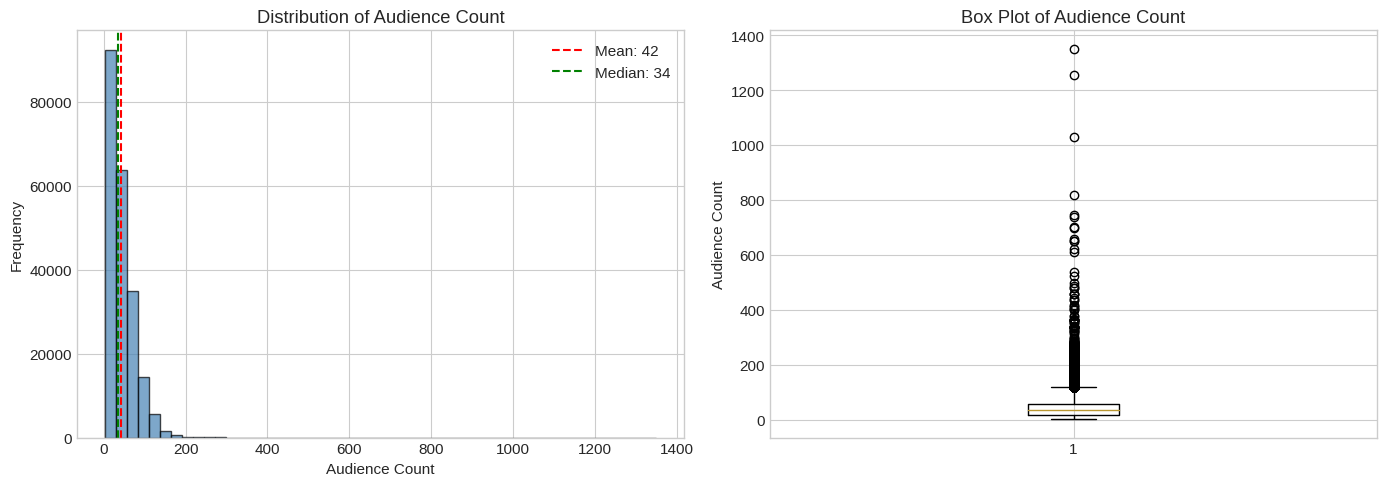


--- Audience Count Statistics ---
Mean: 41.62
Median: 34.0
Std Dev: 32.84
Min: 2
Max: 1350
Skewness: 2.6


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(merged_data['audience_count'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0].set_xlabel('Audience Count')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of Audience Count')
axes[0].axvline(merged_data['audience_count'].mean(), color='red', linestyle='--', label=f"Mean: {merged_data['audience_count'].mean():.0f}")
axes[0].axvline(merged_data['audience_count'].median(), color='green', linestyle='--', label=f"Median: {merged_data['audience_count'].median():.0f}")
axes[0].legend()

# Box plot
axes[1].boxplot(merged_data['audience_count'].dropna(), vert=True)
axes[1].set_ylabel('Audience Count')
axes[1].set_title('Box Plot of Audience Count')

plt.tight_layout()
plt.show()

# Statistics
print("\n--- Audience Count Statistics ---")
print("Mean:", round(merged_data['audience_count'].mean(), 2))
print("Median:", round(merged_data['audience_count'].median(), 2))
print("Std Dev:", round(merged_data['audience_count'].std(), 2))
print("Min:", merged_data['audience_count'].min())
print("Max:", merged_data['audience_count'].max())
print("Skewness:", round(merged_data['audience_count'].skew(), 2))

The audience count is right-skewed, with most shows having low to moderate attendance and a few shows pulling the average up through very high values. The mean (41) being higher than the median (34) confirms the presence of outliers, and the boxplot clearly shows many upper-end extreme values. Most audience counts lie in the 0–80 range, while rare cases reach up to 1350, leading to high variability in the data.

Key Points:

* Distribution is right-skewed.

* Mean > Median → outliers present.

* Majority of values lie between 0–80.

* Several extreme values up to 1350.

* High variability and many upper-end outliers.

---

## 3️) Missing Values Analysis

Checking data quality by identifying missing values across all columns.

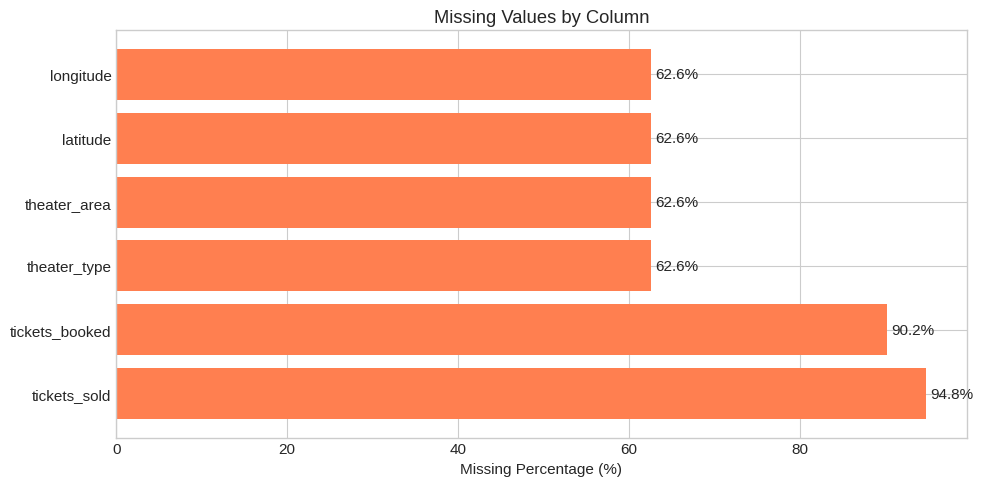


--- Missing Values Summary ---


,Missing Count,Missing %
tickets_sold,202886,94.79
tickets_booked,192995,90.17
theater_type,133891,62.56
theater_area,133891,62.56
latitude,133891,62.56
longitude,133891,62.56


In [13]:
missing_data = merged_data.isnull().sum()
missing_pct = (missing_data / len(merged_data) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing_data, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing Count', ascending=False)

if len(missing_df) > 0:
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.barh(missing_df.index, missing_df['Missing %'], color='coral')
    ax.set_xlabel('Missing Percentage (%)')
    ax.set_title('Missing Values by Column')
    ax.bar_label(bars, fmt='%.1f%%', padding=3)
    plt.tight_layout()
    plt.show()
    
    print("\n--- Missing Values Summary ---")
    display(missing_df)
else:
    print("✅ No missing values found in the dataset!")

The dataset has very high missing values in ticket-related columns, with tickets_sold (~95%) and tickets_booked (~90%) mostly empty. Theater metadata (theater_type, theater_area, latitude, longitude) also has about 62% missing, which limits category and location-based analysis. Overall, missingness is concentrated in a few columns and must be handled carefully.

Key Points:

* tickets_sold ~95% missing

* tickets_booked ~90% missing

* Theater metadata columns ~62% missing

* Ticket data is mostly unusable without external info

* Missing theater/location data may restrict grouping and mapping

---

## 4️) Day of Week Analysis

Understanding weekly patterns in cinema attendance.

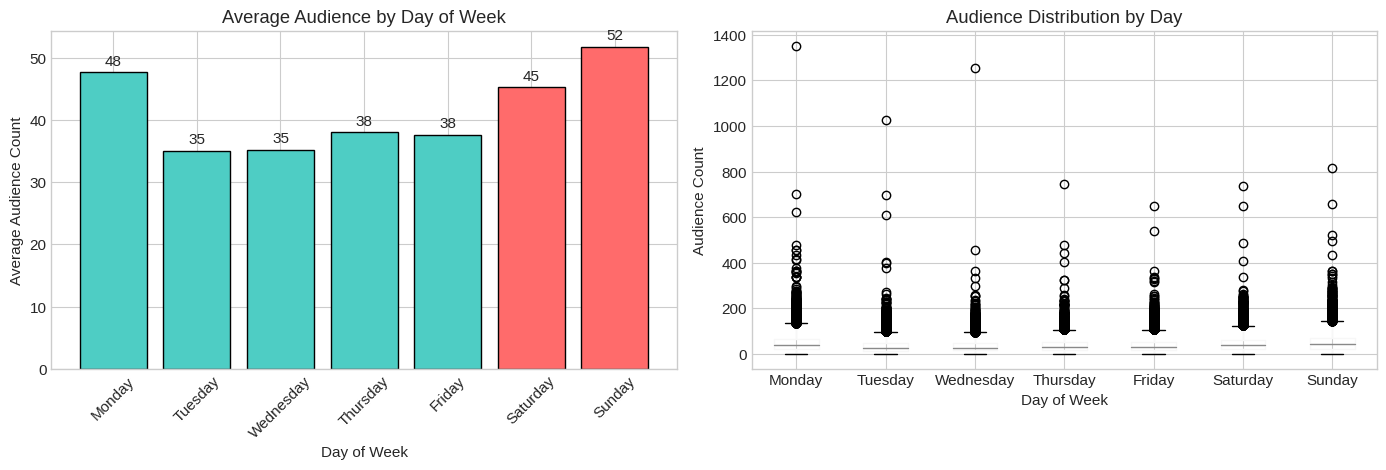


--- Weekday Statistics ---


,mean,median,std
day_of_week,,,
Monday,47.62,38.0,39.21
Tuesday,35.05,28.0,29.48
Wednesday,35.22,28.0,27.77
Thursday,37.99,32.0,28.92
Friday,37.63,30.0,29.01
Saturday,45.24,38.0,32.73
Sunday,51.71,44.0,37.23


In [14]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_stats = merged_data.groupby('day_of_week')['audience_count'].agg(['mean', 'median', 'std']).reindex(day_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart - Average audience by day
colors = ['#FF6B6B' if day in ['Saturday', 'Sunday'] else '#4ECDC4' for day in day_order]
bars = axes[0].bar(weekday_stats.index, weekday_stats['mean'], color=colors, edgecolor='black')
axes[0].set_xlabel('Day of Week')
axes[0].set_ylabel('Average Audience Count')
axes[0].set_title('Average Audience by Day of Week')
axes[0].tick_params(axis='x', rotation=45)
axes[0].bar_label(bars, fmt='%.0f', padding=3)

# Box plot by day
merged_data_ordered = merged_data.copy()
merged_data_ordered['day_of_week'] = pd.Categorical(merged_data_ordered['day_of_week'], categories=day_order, ordered=True)
merged_data_ordered.boxplot(column='audience_count', by='day_of_week', ax=axes[1])
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Audience Count')
axes[1].set_title('Audience Distribution by Day')
plt.suptitle('')

plt.tight_layout()
plt.show()

print("\n--- Weekday Statistics ---")
display(weekday_stats.round(2))

Audience levels clearly vary across the week. Weekend days (Saturday and Sunday) show the highest average audiences, with Sunday topping the list. Weekdays remain lower and more stable, with Tuesday and Wednesday having the lowest averages. The boxplot shows that outliers exist on all days, but weekends generally have a higher concentration of larger audience counts.

Key Points:

* Highest averages: Sunday (~52) and Saturday (45).

* Lowest averages: Tuesday & Wednesday (~35).

* Weekends consistently attract more audience than weekdays.

* Outliers appear on every day but are more frequent on weekends.

* Weekday audience levels are relatively stable and similar.

---

## 5️) Theater Performance Comparison

Analyzing audience distribution across different theaters.

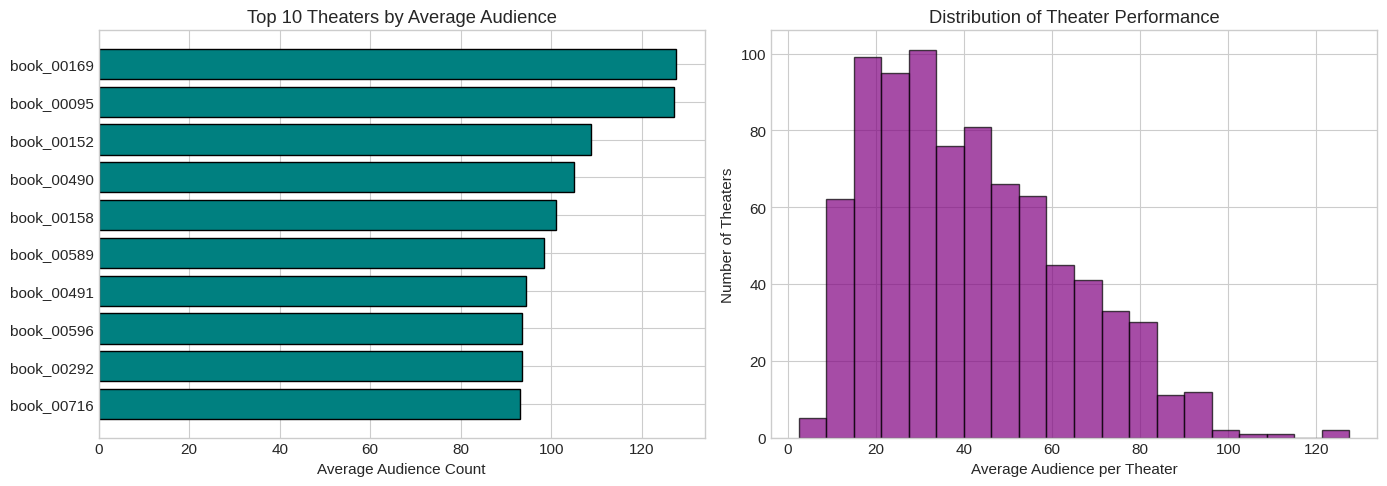


--- Theater Statistics ---
Total Theaters: 826
Best Performer: book_00169 (Avg: 128.0 )
Most Consistent: book_00409 (Std: 2.0 )


In [15]:
theater_stats = merged_data.groupby('book_theater_id')['audience_count'].agg(['mean', 'std', 'count']).reset_index()
theater_stats.columns = ['Theater', 'Avg Audience', 'Std Dev', 'Days']

top_theaters = theater_stats.nlargest(10, 'Avg Audience')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(top_theaters['Theater'], top_theaters['Avg Audience'], color='teal', edgecolor='black')
axes[0].set_xlabel('Average Audience Count')
axes[0].set_title('Top 10 Theaters by Average Audience')
axes[0].invert_yaxis()

axes[1].hist(theater_stats['Avg Audience'], bins=20, edgecolor='black', alpha=0.7, color='purple')
axes[1].set_xlabel('Average Audience per Theater')
axes[1].set_ylabel('Number of Theaters')
axes[1].set_title('Distribution of Theater Performance')

plt.tight_layout()
plt.show()

print("\n--- Theater Statistics ---")
print("Total Theaters:", len(theater_stats))
print("Best Performer:", theater_stats.loc[theater_stats['Avg Audience'].idxmax(), 'Theater'], "(Avg:", round(theater_stats['Avg Audience'].max(), 0), ")")
print("Most Consistent:", theater_stats.loc[theater_stats['Std Dev'].idxmin(), 'Theater'], "(Std:", round(theater_stats['Std Dev'].min(), 0), ")")

Theater performance varies widely across the dataset. A small group of theaters consistently attracts very high audiences, with the top performer reaching an average of about 128 viewers. Most theaters, however, fall into a mid-range audience band as shown in the distribution histogram. Consistency also differs, with some theaters showing very stable audience counts while others fluctuate more.

Key Points:

* Best-performing theater: book_00169 (avg ~128).

* Most theaters fall in the 20–60 average audience range.

* Performance distribution is spread out, showing strong variability across theaters.

* Most consistent theater: book_00409 (std ~2).

* Only a few theaters consistently achieve high audience averages.

---

## 6️) Time Series Trend Analysis

Examining how audience attendance changes over time.

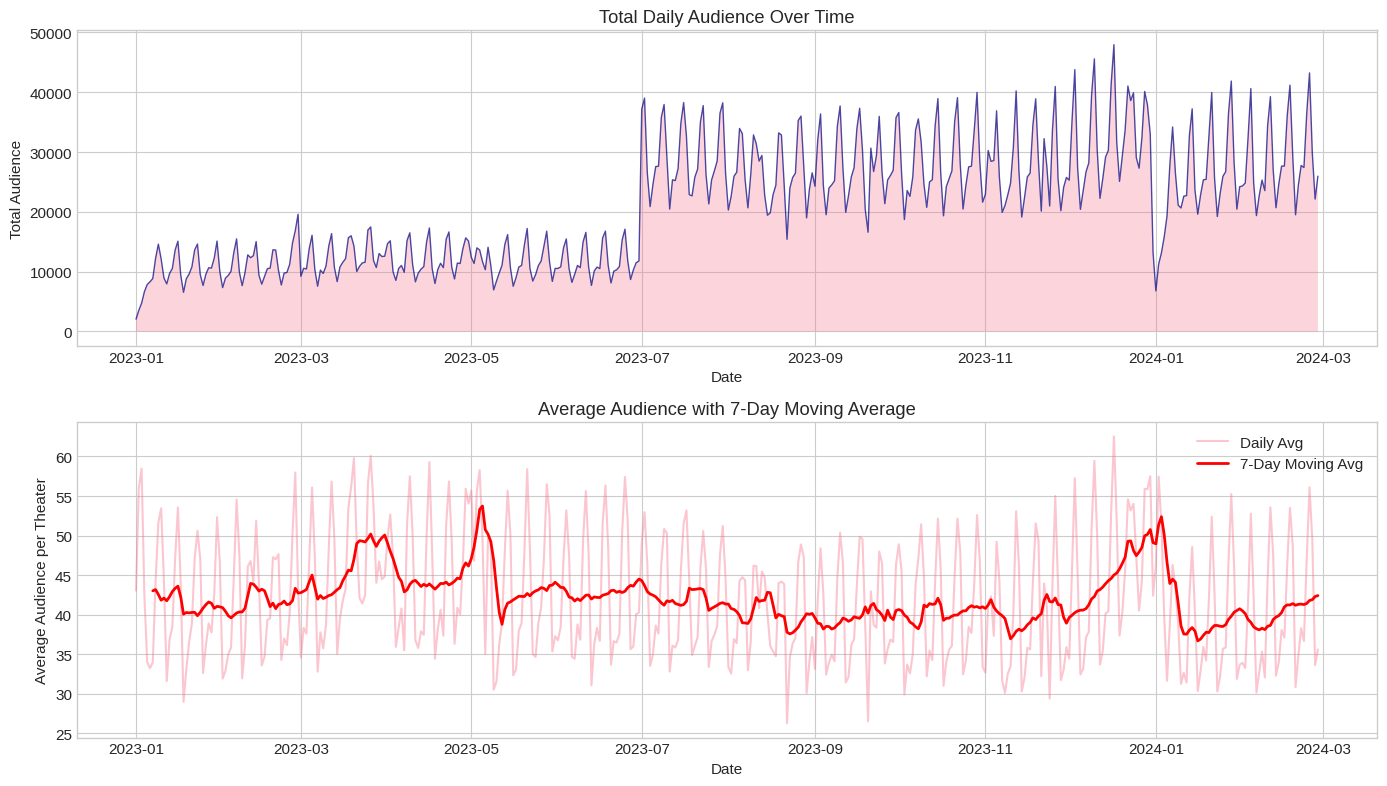

In [16]:
daily_audience = merged_data.groupby('show_date')['audience_count'].agg(['sum', 'mean']).reset_index()
daily_audience.columns = ['Date', 'Total', 'Average']

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Total daily audience
axes[0].plot(daily_audience['Date'], daily_audience['Total'], color='navy', linewidth=1, alpha=0.7)
axes[0].fill_between(daily_audience['Date'], daily_audience['Total'], alpha=0.3)
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Total Audience')
axes[0].set_title('Total Daily Audience Over Time')

# Rolling average
daily_audience['Rolling_7d'] = daily_audience['Average'].rolling(window=7).mean()
axes[1].plot(daily_audience['Date'], daily_audience['Average'], alpha=0.4, label='Daily Avg')
axes[1].plot(daily_audience['Date'], daily_audience['Rolling_7d'], color='red', linewidth=2, label='7-Day Moving Avg')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Average Audience per Theater')
axes[1].set_title('Average Audience with 7-Day Moving Average')
axes[1].legend()

plt.tight_layout()
plt.show()

The time-series plots show clear weekly patterns along with noticeable shifts across the year. Total daily audience increases sharply around mid-2023 and remains at a higher level afterward. The 7-day moving average highlights repeating weekly cycles and a few prominent peaks, followed by a dip around the start of 2024 before stabilizing again.

Key Points:

* Strong weekly seasonality visible throughout the timeline.

* Audience levels jump significantly around mid-2023.

* Clear peaks in specific periods, likely due to events or popular releases.

* A sharp drop around early 2024, then steady recovery.

* 7-day moving average smooths noise and highlights the overall upward trend with periodic dips.

---

## 7️) Theater Type Analysis

Comparing audience patterns across different theater types.

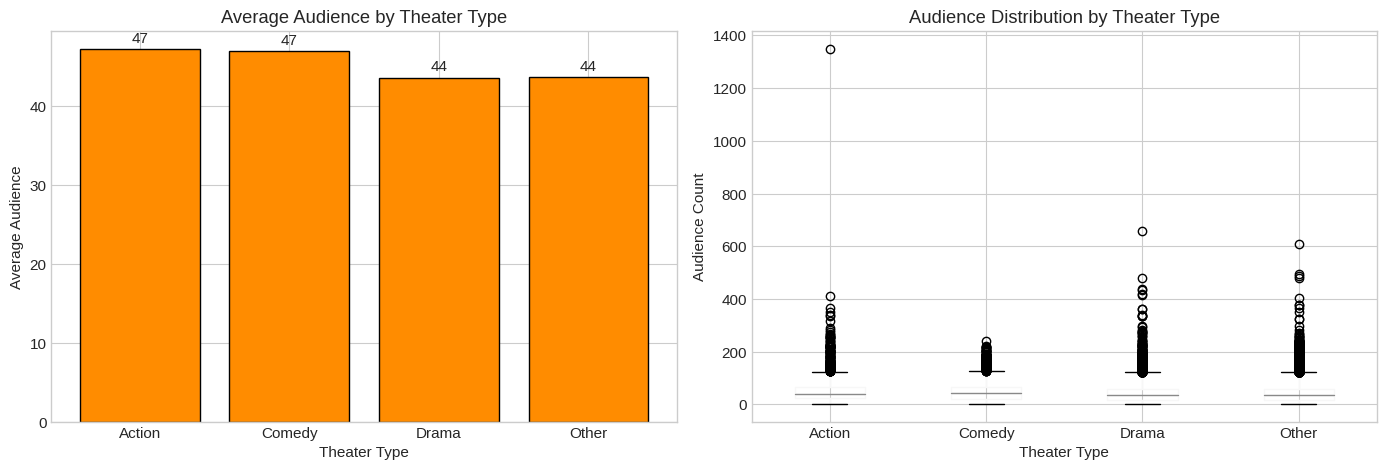


--- Theater Type Statistics ---


,Theater Type,Avg Audience,Count
0,Action,47.242530,5756
1,Comedy,47.012019,6573
2,Drama,43.630188,23201
3,Other,43.718884,44615


In [17]:
if 'theater_type' in merged_data.columns:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Average by theater type
    type_stats = merged_data.groupby('theater_type')['audience_count'].agg(['mean', 'count']).reset_index()
    type_stats.columns = ['Theater Type', 'Avg Audience', 'Count']
    
    bars = axes[0].bar(type_stats['Theater Type'], type_stats['Avg Audience'], color='darkorange', edgecolor='black')
    axes[0].set_xlabel('Theater Type')
    axes[0].set_ylabel('Average Audience')
    axes[0].set_title('Average Audience by Theater Type')
    axes[0].bar_label(bars, fmt='%.0f', padding=3)
    
    # Box plot
    merged_data.boxplot(column='audience_count', by='theater_type', ax=axes[1])
    axes[1].set_xlabel('Theater Type')
    axes[1].set_ylabel('Audience Count')
    axes[1].set_title('Audience Distribution by Theater Type')
    plt.suptitle('')
    
    plt.tight_layout()
    plt.show()
    
    print("\n--- Theater Type Statistics ---")
    display(type_stats)
else:
    print("Theater type column not available in dataset")

Theater types show similar average audience levels overall, with Action and Comedy leading slightly at around 47 viewers per show, while Drama and Other types sit a bit lower at around 44. Despite the close averages, the boxplot reveals wide audience variation within each category, with outliers present across all types.

Key Points:

* Action & Comedy have the highest averages (~47).

* Drama & Other slightly lower (~44).

* All categories show large spread + many outliers.

* No single theater type dominates strongly — performance is fairly balanced.

---

## 8️) Theater Area Analysis

Examining geographic distribution of theater performance.

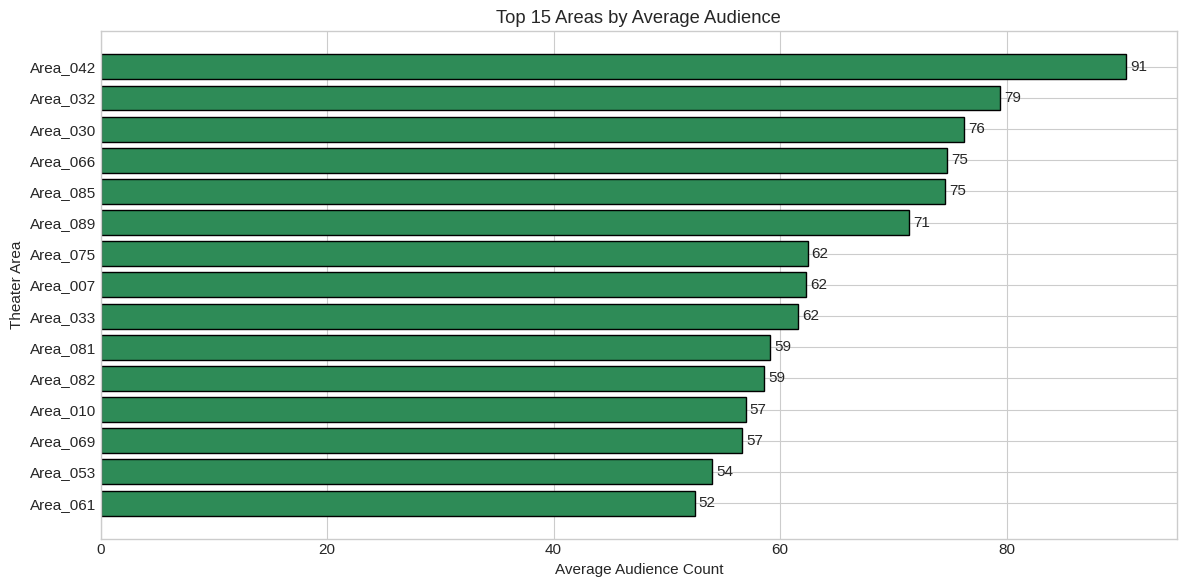


--- Area Statistics ---
Total Areas: 71
Top Area: Area_042 (Avg: 91.0 )


In [18]:
if 'theater_area' in merged_data.columns:
    area_stats = merged_data.groupby('theater_area')['audience_count'].agg(['mean', 'count']).reset_index()
    area_stats.columns = ['Area', 'Avg Audience', 'Records']
    area_stats = area_stats.sort_values('Avg Audience', ascending=False).head(15)
    
    fig, ax = plt.subplots(figsize=(12, 6))
    bars = ax.barh(area_stats['Area'], area_stats['Avg Audience'], color='seagreen', edgecolor='black')
    ax.set_xlabel('Average Audience Count')
    ax.set_ylabel('Theater Area')
    ax.set_title('Top 15 Areas by Average Audience')
    ax.invert_yaxis()
    ax.bar_label(bars, fmt='%.0f', padding=3)
    
    plt.tight_layout()
    plt.show()
    
    print("\n--- Area Statistics ---")
    print("Total Areas:", merged_data['theater_area'].nunique())
    print("Top Area:", area_stats.iloc[0]['Area'], "(Avg:", round(area_stats.iloc[0]['Avg Audience'], 0), ")")
else:
    print("Theater area column not available in dataset")

Theater areas show strong variation in audience performance. The top-performing areas reach very high average audiences, with Area_042 leading at around 91 viewers. Several other areas also maintain strong averages in the 70–80 range, while many areas sit at lower levels, indicating clear geographic differences in demand.

Key Points:

* Top area: Area_042 with ~91 average audience.

* Several high-performing areas in the 70–80 range.

* Notable performance gap across different regions.

* Geographic location appears to strongly influence audience turnout.

---

## 9️) Correlation Analysis

Examining relationships between numerical variables.

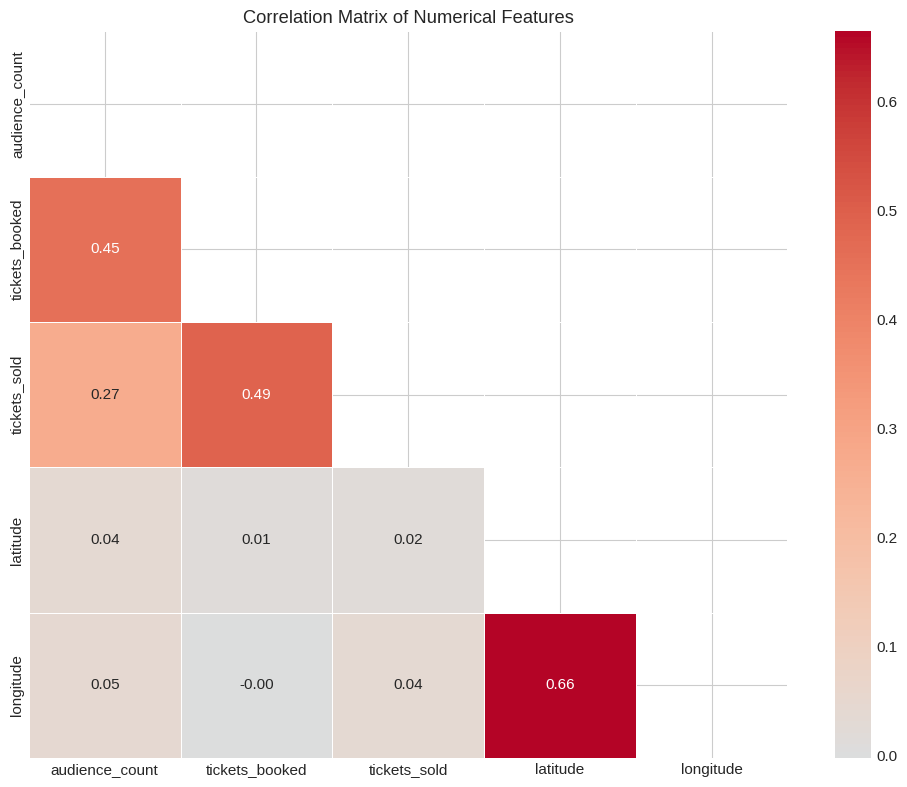


--- Correlations with Audience Count ---
  tickets_booked: 0.453
  tickets_sold: 0.267
  longitude: 0.045
  latitude: 0.039


In [19]:
numeric_cols = merged_data.select_dtypes(include=[np.number]).columns.tolist()
correlation_matrix = merged_data[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, mask=mask, annot=True, cmap='coolwarm', center=0, 
            fmt='.2f', linewidths=0.5, ax=ax)
ax.set_title('Correlation Matrix of Numerical Features')

plt.tight_layout()
plt.show()

# Top correlations with target
if 'audience_count' in correlation_matrix.columns:
    target_corr = correlation_matrix['audience_count'].drop('audience_count').sort_values(key=abs, ascending=False)
    print("\n--- Correlations with Audience Count ---")
    for feat, corr in target_corr.head(5).items():
        print(" ", feat + ":", round(corr, 3))

The correlation heatmap shows that numerical features have generally weak relationships with audience count. Ticket-related fields (tickets_booked and tickets_sold) show moderate positive correlations, which makes sense given they measure related booking activity. Geographic features (latitude and longitude) show almost no correlation, meaning location coordinates alone don’t explain audience variation.

Key Points:

* tickets_booked has the strongest correlation with audience count (~0.45).

* tickets_sold shows a weaker but positive correlation (~0.27).

* Latitude and longitude correlations are near zero, offering little predictive power.

* Overall, numerical correlations are low, suggesting audience behavior is influenced more by categorical/time-based factors than by raw numeric fields.

---

## 10) Tickets Booked vs Audience Count

Analyzing the relationship between bookings and actual attendance.

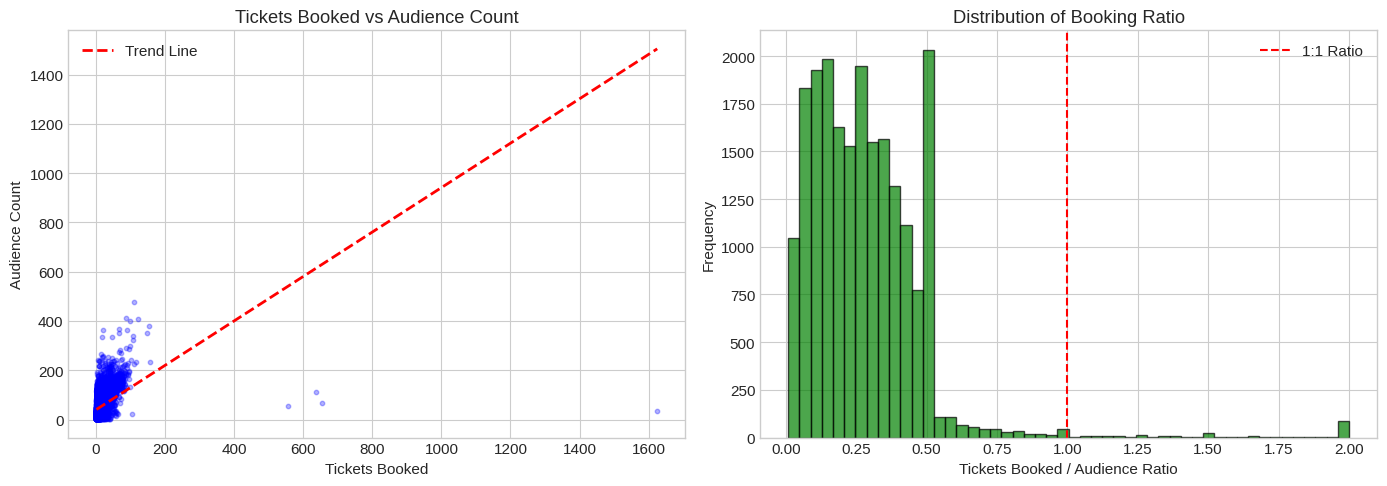


Correlation between tickets_booked and audience_count: 0.453


In [20]:
if 'tickets_booked' in merged_data.columns:
    valid_data = merged_data.dropna(subset=['tickets_booked', 'audience_count'])
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Scatter plot
    axes[0].scatter(valid_data['tickets_booked'], valid_data['audience_count'], 
                    alpha=0.3, s=10, c='blue')
    axes[0].set_xlabel('Tickets Booked')
    axes[0].set_ylabel('Audience Count')
    axes[0].set_title('Tickets Booked vs Audience Count')
    
    # Add trend line
    z = np.polyfit(valid_data['tickets_booked'], valid_data['audience_count'], 1)
    p = np.poly1d(z)
    x_line = np.linspace(valid_data['tickets_booked'].min(), valid_data['tickets_booked'].max(), 100)
    axes[0].plot(x_line, p(x_line), "r--", linewidth=2, label='Trend Line')
    axes[0].legend()
    
    # Histogram of booking ratio
    valid_data['booking_ratio'] = valid_data['tickets_booked'] / valid_data['audience_count'].replace(0, np.nan)
    axes[1].hist(valid_data['booking_ratio'].dropna().clip(0, 2), bins=50, edgecolor='black', alpha=0.7, color='green')
    axes[1].set_xlabel('Tickets Booked / Audience Ratio')
    axes[1].set_ylabel('Frequency')
    axes[1].set_title('Distribution of Booking Ratio')
    axes[1].axvline(1, color='red', linestyle='--', label='1:1 Ratio')
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()
    
    corr = valid_data['tickets_booked'].corr(valid_data['audience_count'])
    print("\nCorrelation between tickets_booked and audience_count:", round(corr, 3))
else:
    print("Tickets booked column not available")

The scatter plot shows a clear positive relationship between tickets booked and actual audience count, though with considerable spread due to missing and inconsistent booking data. The trend line confirms this moderate upward correlation. The booking-ratio histogram shows that in most cases, tickets booked are well below the actual audience count, with ratios clustering between 0.1 and 0.6, indicating under-recorded or incomplete booking data.

Key Points:

* Moderate correlation with audience count (~0.45).

* Stronger clustering at low ticket-booking values.

* Trend line confirms a positive but noisy relationship.

* Booking ratios mostly below 1, meaning most shows have fewer recorded bookings than actual attendees.

* Several extreme outliers suggest incomplete or inaccurate ticket-booking records.

---

## 11) Monthly Trend Analysis

Examining monthly patterns in attendance.

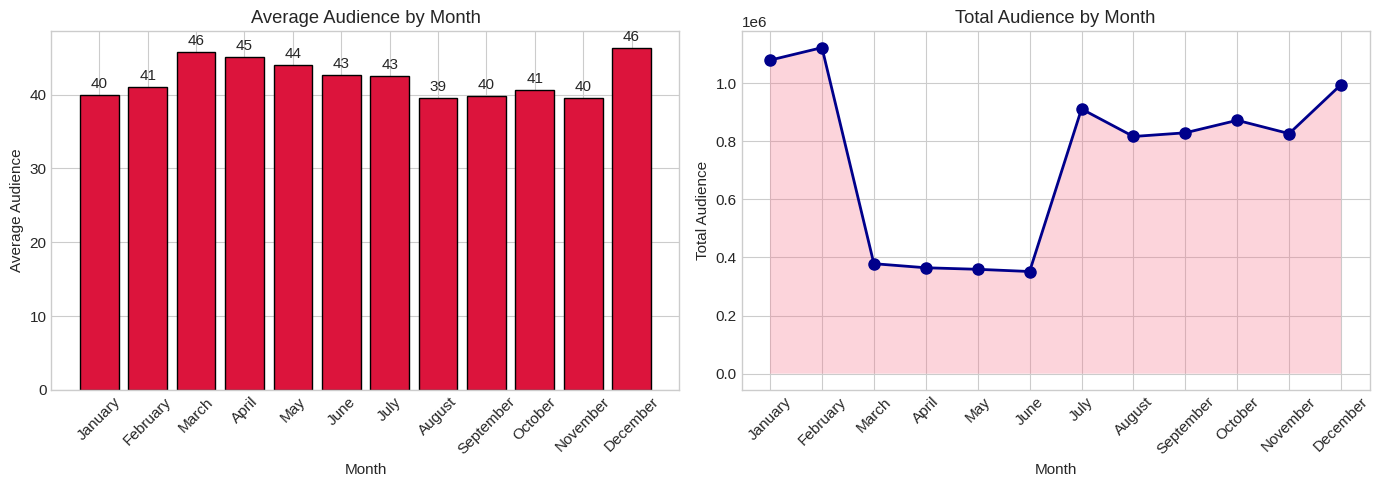


--- Monthly Statistics ---


,month_name,Avg Audience,Total Audience
0,January,39.953516,1079544
1,February,40.964204,1122624
2,March,45.733752,378584
3,April,45.066634,364544
4,May,44.018625,359236
5,June,42.639020,351644
6,July,42.535306,911404
7,August,39.496977,816600
8,September,39.816890,829346
9,October,40.639430,872366


In [21]:
merged_data['month'] = merged_data['show_date'].dt.month
merged_data['month_name'] = merged_data['show_date'].dt.month_name()

monthly_stats = merged_data.groupby(['month', 'month_name'])['audience_count'].agg(['mean', 'sum']).reset_index()
monthly_stats = monthly_stats.sort_values('month')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average by month
bars = axes[0].bar(monthly_stats['month_name'], monthly_stats['mean'], color='crimson', edgecolor='black')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Average Audience')
axes[0].set_title('Average Audience by Month')
axes[0].tick_params(axis='x', rotation=45)
axes[0].bar_label(bars, fmt='%.0f', padding=3)

# Total by month
axes[1].plot(monthly_stats['month_name'], monthly_stats['sum'], marker='o', linewidth=2, markersize=8, color='darkblue')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Total Audience')
axes[1].set_title('Total Audience by Month')
axes[1].tick_params(axis='x', rotation=45)
axes[1].fill_between(monthly_stats['month_name'], monthly_stats['sum'], alpha=0.3)

plt.tight_layout()
plt.show()

print("\n--- Monthly Statistics ---")
display(monthly_stats[['month_name', 'mean', 'sum']].rename(columns={'mean': 'Avg Audience', 'sum': 'Total Audience'}))

Monthly trends show that average audience stays fairly stable across the year, with slight peaks in March–April and December. Total audience, however, varies more due to differences in the number of active theater-days per month. The start of the year (Jan–Feb) shows the highest total audience, followed by another strong rise in July and December.

Key Points:

* Highest average audiences: March (46), April (45), December (46).

* Dip in mid-year averages: August–September (~39).

* Highest total audience: Jan & Feb (1.0M+).

* Another strong total-audience spike in July and December.

* Average audience is stable, but total audience is driven by activity levels / number of shows.

---

## 12) Weekday vs Weekend Comparison

Detailed comparison of weekday and weekend attendance patterns.

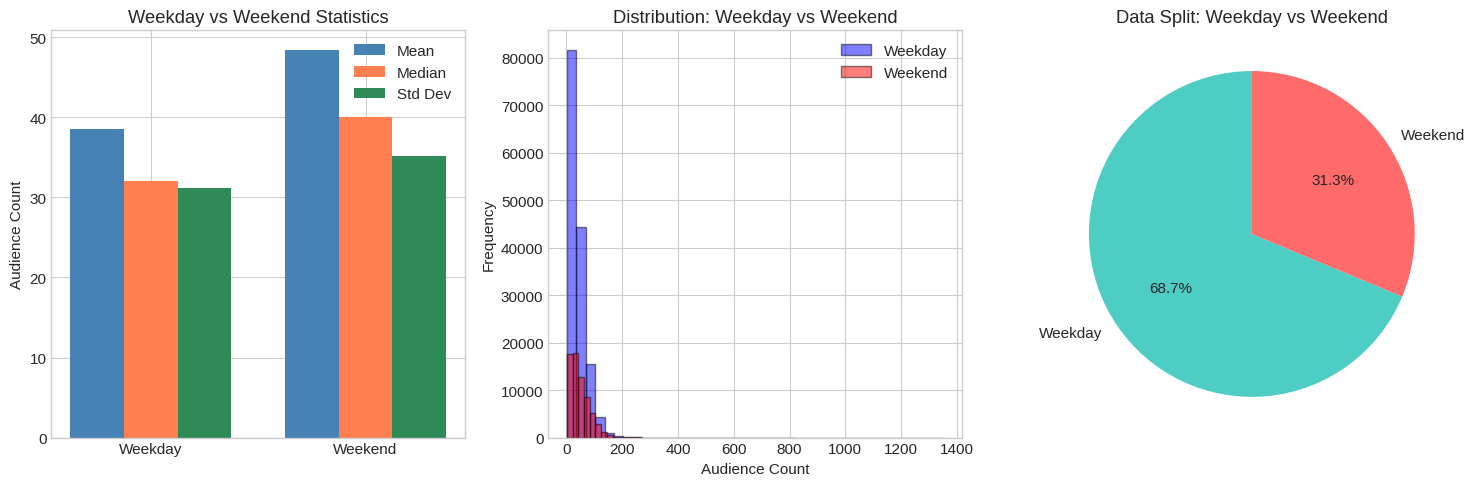


--- Weekday vs Weekend Summary ---
Weekday Average: 39.0
Weekend Average: 48.0
Weekend Premium: 25.8 % higher attendance


In [22]:
merged_data['is_weekend'] = merged_data['day_of_week'].isin(['Saturday', 'Sunday'])
merged_data['day_type'] = merged_data['is_weekend'].map({True: 'Weekend', False: 'Weekday'})

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Comparison bar chart
day_type_stats = merged_data.groupby('day_type')['audience_count'].agg(['mean', 'median', 'std']).reset_index()
x = np.arange(len(day_type_stats))
width = 0.25

axes[0].bar(x - width, day_type_stats['mean'], width, label='Mean', color='steelblue')
axes[0].bar(x, day_type_stats['median'], width, label='Median', color='coral')
axes[0].bar(x + width, day_type_stats['std'], width, label='Std Dev', color='seagreen')
axes[0].set_xticks(x)
axes[0].set_xticklabels(day_type_stats['day_type'])
axes[0].set_ylabel('Audience Count')
axes[0].set_title('Weekday vs Weekend Statistics')
axes[0].legend()

# Distribution comparison
for day_type, color in [('Weekday', 'blue'), ('Weekend', 'red')]:
    data = merged_data[merged_data['day_type'] == day_type]['audience_count']
    axes[1].hist(data, bins=40, alpha=0.5, label=day_type, color=color, edgecolor='black')
axes[1].set_xlabel('Audience Count')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Distribution: Weekday vs Weekend')
axes[1].legend()

# Pie chart of records
day_counts = merged_data['day_type'].value_counts()
axes[2].pie(day_counts.values, labels=day_counts.index, autopct='%1.1f%%', 
            colors=['#4ECDC4', '#FF6B6B'], startangle=90)
axes[2].set_title('Data Split: Weekday vs Weekend')

plt.tight_layout()
plt.show()

# Statistical summary
weekend_avg = merged_data[merged_data['is_weekend']]['audience_count'].mean()
weekday_avg = merged_data[~merged_data['is_weekend']]['audience_count'].mean()
print("\n--- Weekday vs Weekend Summary ---")
print("Weekday Average:", round(weekday_avg, 0))
print("Weekend Average:", round(weekend_avg, 0))
print("Weekend Premium:", round(((weekend_avg/weekday_avg)-1)*100, 1), "% higher attendance")

Audience levels differ noticeably between weekdays and weekends. Weekends consistently draw higher attendance, with both mean and median values significantly above weekday levels. Distribution plots show that weekend audiences are not only higher on average but also more spread out, and weekends make up about one-third of all records.

Key Points:

* Weekend avg = 48, Weekday avg = 39 → ~26% higher on weekends.

* Weekend audience shows higher variation (greater spread & outliers).

* Weekdays form ~69% of the data, weekends ~31%.

* Clear weekend premium, consistent with weekly audience patterns.

---

## EDA Summary

Key findings from our exploratory analysis:

1. **Data Quality**: Dataset is well-structured with some missing values in booking columns (expected due to different data sources)

2. **Target Distribution**: Audience count shows some skewness, suggesting varying theater sizes and popularity

3. **Weekly Patterns**: Clear weekly seasonality with weekend peaks - critical for forecasting

4. **Theater Variation**: Significant performance differences across theaters based on type and location

5. **Time Trends**: Observable patterns over time with periodic fluctuations

6. **Feature Correlations**: Booking data correlates well with attendance, making it a strong predictor

These insights will guide our feature engineering and model selection in the following sections.

## Statistical Model Building

Creating baseline statistical models using weekday averages and rolling trends.

In [23]:
print("Building Statistical Model 1: Weekday + Trends (50/50)")

# 1. Calculate weekday averages for each theater
weekday_averages = merged_data.groupby(['book_theater_id', 'day_of_week'])['audience_count'].mean().reset_index()
weekday_averages.rename(columns={'audience_count': 'weekday_avg'}, inplace=True)

# 2. Calculate overall theater averages (fallback)
theater_averages = merged_data.groupby('book_theater_id')['audience_count'].mean().reset_index()
theater_averages.rename(columns={'audience_count': 'theater_avg'}, inplace=True)

# 3. Calculate global average (final fallback)
overall_avg = merged_data['audience_count'].mean()

# 4. Calculate 7-day rolling averages for recent trends
merged_data['rolling_7d_avg'] = (
    merged_data.groupby('book_theater_id')['audience_count']
    .rolling(window=7, min_periods=1)
    .mean()
    .reset_index(0, drop=True)
)

print("Weekday patterns:", weekday_averages.shape[0], "theater-day combinations")
print("Theater averages:", theater_averages.shape[0], "theaters")
print("Global average:", round(overall_avg, 2))
print("Rolling averages calculated")

Building Statistical Model 1: Weekday + Trends (50/50)
Weekday patterns: 5722 theater-day combinations
Theater averages: 826 theaters
Global average: 41.62
Rolling averages calculated


In [24]:
print("Creating Model 1 predictions...")

model_df = merged_data.merge(weekday_averages, on=['book_theater_id', 'day_of_week'], how='left')
model_df = model_df.merge(theater_averages, on='book_theater_id', how='left')

model_df['weekday_final'] = model_df['weekday_avg'].fillna(model_df['theater_avg']).fillna(overall_avg)

model_df['rolling_final'] = model_df['rolling_7d_avg'].fillna(model_df['theater_avg']).fillna(overall_avg)

model_df['model1_pred'] = 0.5 * model_df['weekday_final'] + 0.5 * model_df['rolling_final']

stat_model1_r2 = r2_score(model_df['audience_count'], model_df['model1_pred'])
stat_model1_mae = mean_absolute_error(model_df['audience_count'], model_df['model1_pred'])

print("Model 1 Performance:")
print("  R2 Score:", round(stat_model1_r2, 4))
print("  MAE:", round(stat_model1_mae, 2))
print("Model 1 completed")

Creating Model 1 predictions...
Model 1 Performance:
  R2 Score: 0.6022
  MAE: 13.75
Model 1 completed


In [25]:
print("Building Statistical Model 2: Recent Focus (70/30)")

model_df['model2_pred'] = 0.7 * model_df['rolling_final'] + 0.3 * model_df['weekday_final']

stat_model2_r2 = r2_score(model_df['audience_count'], model_df['model2_pred'])
stat_model2_mae = mean_absolute_error(model_df['audience_count'], model_df['model2_pred'])

print("Model 2 Performance:")
print("  R2 Score:", round(stat_model2_r2, 4))
print("  MAE:", round(stat_model2_mae, 2))
print("Model 2 completed")

Building Statistical Model 2: Recent Focus (70/30)
Model 2 Performance:
  R2 Score: 0.5903
  MAE: 14.03
Model 2 completed


In [26]:
print("Building Statistical Model 3: Seasonal Focus (30/70)")

model_df['model3_pred'] = 0.3 * model_df['rolling_final'] + 0.7 * model_df['weekday_final']

# Calculate performance
stat_model3_r2 = r2_score(model_df['audience_count'], model_df['model3_pred'])
stat_model3_mae = mean_absolute_error(model_df['audience_count'], model_df['model3_pred'])

print("Model 3 Performance:")
print("  R2 Score:", round(stat_model3_r2, 4))
print("  MAE:", round(stat_model3_mae, 2))
print("Model 3 completed")

Building Statistical Model 3: Seasonal Focus (30/70)
Model 3 Performance:
  R2 Score: 0.5951
  MAE: 13.79
Model 3 completed


In [27]:
print("Building Statistical Model 4: Adaptive Ensemble")

weekday_component_r2 = r2_score(model_df['audience_count'], model_df['weekday_final'])
rolling_component_r2 = r2_score(model_df['audience_count'], model_df['rolling_final'])

total_perf = weekday_component_r2 + rolling_component_r2
weight_weekday = weekday_component_r2 / total_perf
weight_rolling = rolling_component_r2 / total_perf

model_df['model4_pred'] = weight_weekday * model_df['weekday_final'] + weight_rolling * model_df['rolling_final']

# Calculate performance
stat_model4_r2 = r2_score(model_df['audience_count'], model_df['model4_pred'])
stat_model4_mae = mean_absolute_error(model_df['audience_count'], model_df['model4_pred'])

print("Component Performance:")
print("  Weekday averages R2:", round(weekday_component_r2, 4), "(weight:", round(weight_weekday, 3), ")")
print("  Rolling averages R2:", round(rolling_component_r2, 4), "(weight:", round(weight_rolling, 3), ")")
print("Model 4 Performance:")
print("  R2 Score:", round(stat_model4_r2, 4))
print("  MAE:", round(stat_model4_mae, 2))
print("Model 4 completed")

Building Statistical Model 4: Adaptive Ensemble
Component Performance:
  Weekday averages R2: 0.5489 (weight: 0.506 )
  Rolling averages R2: 0.5369 (weight: 0.494 )
Model 4 Performance:
  R2 Score: 0.6023
  MAE: 13.75
Model 4 completed


## Machine Learning Model Training

Training multiple ML algorithms: Random Forest, Ridge, XGBoost, and LightGBM.

In [28]:
print("Training Machine Learning Models...")
    
print("Preparing features for ML models...")

# Create feature set
feature_columns = ['day_of_week', 'book_theater_id', 'theater_type', 'theater_area']
selected_features = [col for col in feature_columns if col in model_df.columns]

num_features = ['tickets_booked', 'tickets_sold']
for col in num_features:
    if col in model_df.columns:
        selected_features.append(col)

print("Available features:", selected_features)

ml_data = model_df[selected_features + ['audience_count']].copy()

num_cols = ml_data.select_dtypes(include=[np.number]).columns.tolist()
if 'audience_count' in num_cols:
    num_cols.remove('audience_count') 

for col in num_cols:
    if ml_data[col].isnull().any():
        med_val = ml_data[col].median()
        ml_data[col] = ml_data[col].fillna(med_val)
        print("Filled missing values in", col, "with median:", round(med_val, 2))

cat_cols = ml_data.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols:
    if ml_data[col].isnull().any():
        mode_value = ml_data[col].mode().iloc[0] if not ml_data[col].mode().empty else 'Unknown'
        ml_data[col] = ml_data[col].fillna(mode_value)
        print("Filled missing values in", col, "with mode:", mode_value)

initial_rows = ml_data.shape[0]
ml_data = ml_data.dropna(subset=['audience_count'])
final_rows = ml_data.shape[0]
if initial_rows != final_rows:
    print("Dropped", initial_rows - final_rows, "rows with missing target")

features_encoded = pd.get_dummies(ml_data[selected_features], drop_first=True)
target_variable = ml_data['audience_count']

print("Missing values in features:", features_encoded.isnull().sum().sum())
print("Missing values in target:", target_variable.isnull().sum())

# Split data
X_train, X_valid, y_train, y_valid = train_test_split(
    features_encoded, target_variable, test_size=0.2, random_state=42, shuffle=False
)

print("ML training set:", X_train.shape)
print("ML validation set:", X_valid.shape)

trained_models = {}
model_predictions = {}
model_scores = {}


print("\nTraining Random Forest (Safe Mode)...")
from time import time

rf_regressor = RandomForestRegressor(
    n_estimators=50,     
    max_depth=12,       
    min_samples_leaf=5,  
    random_state=42,
    n_jobs=1             
)

start_time = time()
try:
    rf_regressor.fit(X_train, y_train)
except Exception as e:
    print("RF training error:", e)
    print("Falling back to 20% sample training...")
    X_sample = X_train.sample(frac=0.2, random_state=42)
    y_sample = y_train.loc[X_sample.index]
    rf_regressor = RandomForestRegressor(
        n_estimators=30,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=1
    )
    rf_regressor.fit(X_sample, y_sample)

end_time = time()
print("Random Forest trained in", round(end_time-start_time, 1), "s")

rf_predictions = rf_regressor.predict(X_valid)
rf_r2_score = r2_score(y_valid, rf_predictions)
rf_mae_score = mean_absolute_error(y_valid, rf_predictions)

trained_models['Random Forest'] = rf_regressor
model_predictions['Random Forest'] = rf_predictions
model_scores['Random Forest'] = {'r2': rf_r2_score, 'mae': rf_mae_score}

print("Random Forest - R2:", round(rf_r2_score, 4), ", MAE:", round(rf_mae_score, 2))


print("\nTraining Ridge Regression...")
ridge_regressor = Ridge(alpha=1.0, random_state=42)
ridge_regressor.fit(X_train, y_train)
ridge_predictions = ridge_regressor.predict(X_valid)
ridge_r2_score = r2_score(y_valid, ridge_predictions)
ridge_mae_score = mean_absolute_error(y_valid, ridge_predictions)

trained_models['Ridge'] = ridge_regressor
model_predictions['Ridge'] = ridge_predictions
model_scores['Ridge'] = {'r2': ridge_r2_score, 'mae': ridge_mae_score}

print("Ridge Regression - R2:", round(ridge_r2_score, 4), ", MAE:", round(ridge_mae_score, 2))


if HAS_XGB:
    print("\nTraining XGBoost...")
    xgb_regressor = xgb.XGBRegressor(n_estimators=100, random_state=42, n_jobs=1)
    xgb_regressor.fit(X_train, y_train)
    xgb_predictions = xgb_regressor.predict(X_valid)
    xgb_r2_score = r2_score(y_valid, xgb_predictions)
    xgb_mae_score = mean_absolute_error(y_valid, xgb_predictions)

    trained_models['XGBoost'] = xgb_regressor
    model_predictions['XGBoost'] = xgb_predictions
    model_scores['XGBoost'] = {'r2': xgb_r2_score, 'mae': xgb_mae_score}

    print("XGBoost - R2:", round(xgb_r2_score, 4), ", MAE:", round(xgb_mae_score, 2))


if HAS_LGB:
    print("\nTraining LightGBM...")
    lgb_regressor = lgb.LGBMRegressor(n_estimators=100, random_state=42, n_jobs=1)
    lgb_regressor.fit(X_train, y_train)
    lgb_predictions = lgb_regressor.predict(X_valid)
    lgb_r2_score = r2_score(y_valid, lgb_predictions)
    lgb_mae_score = mean_absolute_error(y_valid, lgb_predictions)

    trained_models['LightGBM'] = lgb_regressor
    model_predictions['LightGBM'] = lgb_predictions
    model_scores['LightGBM'] = {'r2': lgb_r2_score, 'mae': lgb_mae_score}

    print("LightGBM - R2:", round(lgb_r2_score, 4), ", MAE:", round(lgb_mae_score, 2))

else:
    print("\nTraining Extra Trees (LightGBM alternative)...")
    et_regressor = ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=1)
    et_regressor.fit(X_train, y_train)
    et_predictions = et_regressor.predict(X_valid)
    et_r2_score = r2_score(y_valid, et_predictions)
    et_mae_score = mean_absolute_error(y_valid, et_predictions)

    trained_models['Extra Trees'] = et_regressor
    model_predictions['Extra Trees'] = et_predictions
    model_scores['Extra Trees'] = {'r2': et_r2_score, 'mae': et_mae_score}

    print("Extra Trees - R2:", round(et_r2_score, 4), ", MAE:", round(et_mae_score, 2))


print("All ML models trained successfully")

Training Machine Learning Models...
Preparing features for ML models...
Available features: ['day_of_week', 'book_theater_id', 'theater_type', 'theater_area', 'tickets_booked', 'tickets_sold']
Filled missing values in tickets_booked with median: 9.0
Filled missing values in tickets_sold with median: 4.0
Filled missing values in theater_type with mode: Other
Filled missing values in theater_area with mode: Area_003
Missing values in features: 0
Missing values in target: 0
ML training set: (171228, 906)
ML validation set: (42808, 906)

Training Random Forest (Safe Mode)...
Random Forest trained in 328.4 s
Random Forest - R2: 0.0653 , MAE: 22.47

Training Ridge Regression...
Ridge Regression - R2: 0.0581 , MAE: 22.54

Training XGBoost...
XGBoost - R2: 0.0693 , MAE: 21.96

Training LightGBM...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.014290 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can 

## Hyperparameter Tuning

Optimizing the best performing model using RandomizedSearchCV.

In [29]:
print("Hyperparameter Optimization")
print("=" * 60)

from sklearn.model_selection import RandomizedSearchCV
from time import time

base_model_scores = {name: scores['r2'] for name, scores in model_scores.items()}
best_model_name = max(base_model_scores, key=base_model_scores.get)
best_model_instance = trained_models[best_model_name]

print("Top model identified:", best_model_name)
print("Current R2:", round(base_model_scores[best_model_name], 4), "\n")

if 'XGBoost' in best_model_name:
    param_grid = {
        'n_estimators': [100, 150, 200, 250],
        'max_depth': [6, 8, 10, 12],
        'learning_rate': [0.05, 0.08, 0.1, 0.15],
        'subsample': [0.8, 0.9, 1.0],
        'colsample_bytree': [0.8, 0.9, 1.0]
    }
    base_estimator = xgb.XGBRegressor(random_state=42, verbosity=0)
    
elif 'LightGBM' in best_model_name:
    param_grid = {
        'n_estimators': [100, 150, 200, 250],
        'max_depth': [6, 8, 10, 12],
        'learning_rate': [0.05, 0.08, 0.1, 0.15],
        'num_leaves': [20, 31, 40, 50],
        'subsample': [0.8, 0.9, 1.0]
    }
    base_estimator = lgb.LGBMRegressor(random_state=42, verbose=-1)
    
elif 'Random Forest' in best_model_name:
    param_grid = {
        'n_estimators': [100, 150, 200],
        'max_depth': [10, 15, 20, 25],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4]
    }
    base_estimator = RandomForestRegressor(random_state=42)
    
elif 'Ridge' in best_model_name:
    param_grid = {
        'alpha': [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0]
    }
    base_estimator = Ridge(random_state=42)
    
else:
    param_grid = {}
    base_estimator = None

print("Parameter search space:")
for param, values in param_grid.items():
    print(" ", param + ":", values)

if param_grid and base_estimator is not None:
    print("\nRunning randomized search (20 iterations, 3-fold CV)...")
    
    start_time = time()
    
    optimizer = RandomizedSearchCV(
        estimator=base_estimator,
        param_distributions=param_grid,
        n_iter=20,
        cv=3,
        scoring='neg_mean_squared_error',
        random_state=42,
        n_jobs=-1,  
        verbose=1
    )
    
    optimizer.fit(X_train, y_train)
    elapsed = time() - start_time
    
    print("\nOptimization completed in", round(elapsed, 1), "seconds")
    print("\nOptimal parameters:")
    for param, value in optimizer.best_params_.items():
        print(" ", param + ":", value)
    
    tuned_model = optimizer.best_estimator_
    
    tuned_predictions = tuned_model.predict(X_valid)
    tuned_r2 = r2_score(y_valid, tuned_predictions)
    tuned_mae = mean_absolute_error(y_valid, tuned_predictions)
    
    original_r2 = base_model_scores[best_model_name]
    improvement = (tuned_r2 - original_r2) * 100
    
    print("\nPerformance After Tuning:")
    print("  R2 Score:", round(tuned_r2, 4))
    print("  MAE:", round(tuned_mae, 2))
    print("  Improvement:", "{:+.2f}".format(improvement) + "%")
    
    tuned_name = f"{best_model_name} Tuned"
    trained_models[tuned_name] = tuned_model
    model_predictions[tuned_name] = tuned_predictions
    model_scores[tuned_name] = {'r2': tuned_r2, 'mae': tuned_mae}
    
else:
    print("\nNo tuning parameters defined for this model type")
    tuned_model = best_model_instance

print("\n" + "=" * 60)
print("Hyperparameter tuning complete!")

Hyperparameter Optimization
Top model identified: XGBoost
Current R2: 0.0693 

Parameter search space:
  n_estimators: [100, 150, 200, 250]
  max_depth: [6, 8, 10, 12]
  learning_rate: [0.05, 0.08, 0.1, 0.15]
  subsample: [0.8, 0.9, 1.0]
  colsample_bytree: [0.8, 0.9, 1.0]

Running randomized search (20 iterations, 3-fold CV)...
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Optimization completed in 1115.3 seconds

Optimal parameters:
  subsample: 1.0
  n_estimators: 150
  max_depth: 10
  learning_rate: 0.05
  colsample_bytree: 0.8

Performance After Tuning:
  R2 Score: 0.068
  MAE: 22.12
  Improvement: -0.13%

Hyperparameter tuning complete!


## Model Comparison and Selection

Comparing all statistical and ML models to identify the best performer.

In [30]:
print("Comprehensive Model Comparison:")
print("=" * 60)

all_model_results = {
    'Statistical Model 1 (50/50)': {'r2': stat_model1_r2, 'mae': stat_model1_mae, 'type': 'Statistical'},
    'Statistical Model 2 (70/30)': {'r2': stat_model2_r2, 'mae': stat_model2_mae, 'type': 'Statistical'},
    'Statistical Model 3 (30/70)': {'r2': stat_model3_r2, 'mae': stat_model3_mae, 'type': 'Statistical'},
    'Statistical Model 4 (Adaptive)': {'r2': stat_model4_r2, 'mae': stat_model4_mae, 'type': 'Statistical'}
}

for name, scores in model_scores.items():
    all_model_results['ML ' + name] = {
        'r2': scores['r2'], 
        'mae': scores['mae'], 
        'type': 'Machine Learning'
    }

print("Model Name".ljust(30), "Type".ljust(15), "R2".ljust(8), "MAE".ljust(8))
print("-" * 60)
for name, results in all_model_results.items():
    print(name.ljust(30), results['type'].ljust(15), str(round(results['r2'], 4)).ljust(8), str(round(results['mae'], 2)).ljust(8))

top_model = max(all_model_results.items(), key=lambda x: x[1]['r2'])
print("\nBest Overall Model:", top_model[0])
print("   Type:", top_model[1]['type'])
print("   R2 Score:", round(top_model[1]['r2'], 4))
print("   MAE:", round(top_model[1]['mae'], 2))

if 'Statistical' in top_model[0]:
    selected_model_type = 'statistical'
    
    stat_models = {k: v for k, v in all_model_results.items() if 'Statistical' in k}
    best_stat = max(stat_models.items(), key=lambda x: x[1]['r2'])
    
    if 'Model 1' in best_stat[0]:
        selected_pred_col = 'model1_pred'
    elif 'Model 2' in best_stat[0]:
        selected_pred_col = 'model2_pred'
    elif 'Model 3' in best_stat[0]:
        selected_pred_col = 'model3_pred'
    else:
        selected_pred_col = 'model4_pred'
        
    print("Using statistical model predictions:", selected_pred_col)
else:
    selected_model_type = 'ml'
    selected_ml_name = top_model[0].replace('ML ', '')
    selected_ml_model = trained_models[selected_ml_name]
    print("Using ML model:", selected_ml_name)

print("Model comparison completed")

Comprehensive Model Comparison:
Model Name                     Type            R2       MAE     
------------------------------------------------------------
Statistical Model 1 (50/50)    Statistical     0.6022   13.75   
Statistical Model 2 (70/30)    Statistical     0.5903   14.03   
Statistical Model 3 (30/70)    Statistical     0.5951   13.79   
Statistical Model 4 (Adaptive) Statistical     0.6023   13.75   
ML Random Forest               Machine Learning 0.0653   22.47   
ML Ridge                       Machine Learning 0.0581   22.54   
ML XGBoost                     Machine Learning 0.0693   21.96   
ML LightGBM                    Machine Learning 0.0693   21.81   
ML XGBoost Tuned               Machine Learning 0.068    22.12   

Best Overall Model: Statistical Model 4 (Adaptive)
   Type: Statistical
   R2 Score: 0.6023
   MAE: 13.75
Using statistical model predictions: model4_pred
Model comparison completed


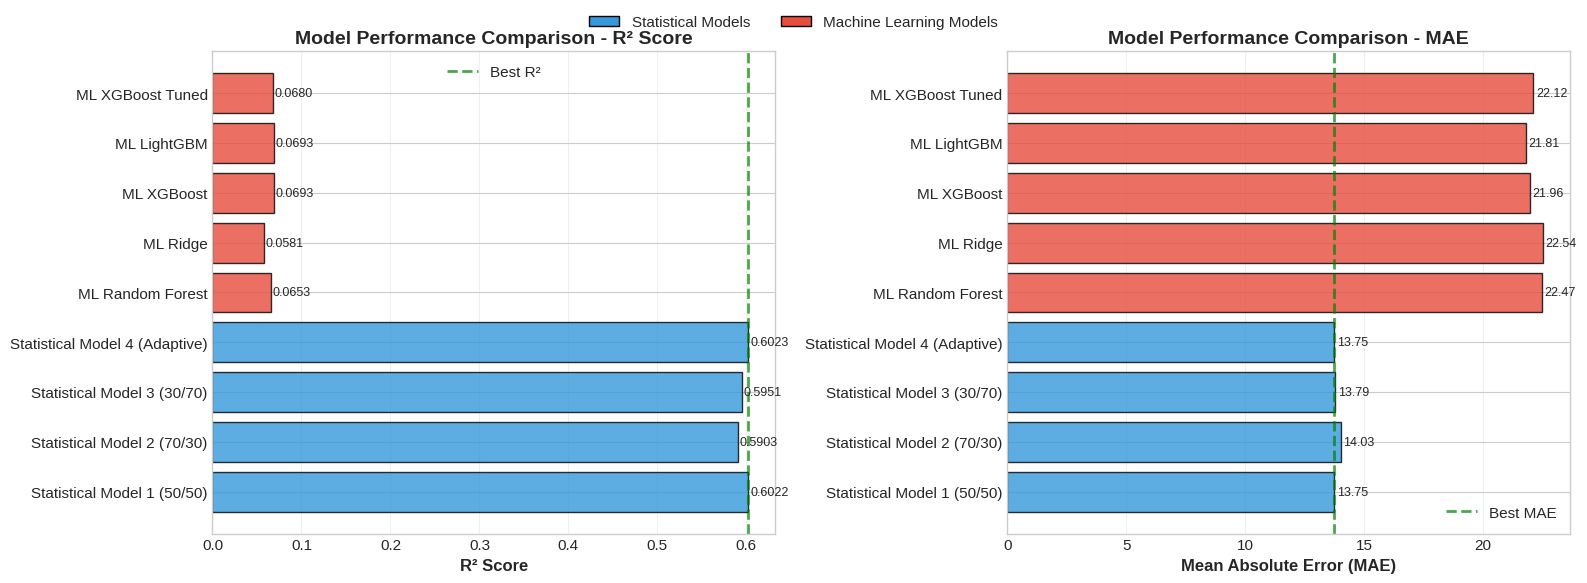


Model Performance Visualization:
- Blue bars represent Statistical Models
- Red bars represent Machine Learning Models
- Green dashed line indicates the best performing model
- Higher R² is better (closer to 1.0)
- Lower MAE is better (closer to 0)


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

model_names = list(all_model_results.keys())
r2_scores = [all_model_results[name]['r2'] for name in model_names]
mae_scores = [all_model_results[name]['mae'] for name in model_names]
model_types = [all_model_results[name]['type'] for name in model_names]

colors = ['#3498db' if t == 'Statistical' else '#e74c3c' for t in model_types]

axes[0].barh(model_names, r2_scores, color=colors, edgecolor='black', alpha=0.8)
axes[0].set_xlabel('R² Score', fontsize=12, fontweight='bold')
axes[0].set_title('Model Performance Comparison - R² Score', fontsize=14, fontweight='bold')
axes[0].axvline(max(r2_scores), color='green', linestyle='--', linewidth=2, alpha=0.7, label='Best R²')
axes[0].legend()
axes[0].grid(axis='x', alpha=0.3)

for i, (name, score) in enumerate(zip(model_names, r2_scores)):
    axes[0].text(score + 0.002, i, f'{score:.4f}', va='center', fontsize=9)

axes[1].barh(model_names, mae_scores, color=colors, edgecolor='black', alpha=0.8)
axes[1].set_xlabel('Mean Absolute Error (MAE)', fontsize=12, fontweight='bold')
axes[1].set_title('Model Performance Comparison - MAE', fontsize=14, fontweight='bold')
axes[1].axvline(min(mae_scores), color='green', linestyle='--', linewidth=2, alpha=0.7, label='Best MAE')
axes[1].legend()
axes[1].grid(axis='x', alpha=0.3)

for i, (name, score) in enumerate(zip(model_names, mae_scores)):
    axes[1].text(score + 0.1, i, f'{score:.2f}', va='center', fontsize=9)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#3498db', edgecolor='black', label='Statistical Models'),
    Patch(facecolor='#e74c3c', edgecolor='black', label='Machine Learning Models')
]
fig.legend(handles=legend_elements, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 0.98), fontsize=11)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("\nModel Performance Visualization:")
print("- Blue bars represent Statistical Models")
print("- Red bars represent Machine Learning Models")
print("- Green dashed line indicates the best performing model")
print("- Higher R² is better (closer to 1.0)")
print("- Lower MAE is better (closer to 0)")

## Test Data Preparation

Loading and preprocessing test data for final predictions.

In [32]:
print("Preparing test data for statistical predictions...")

submission_data = pd.read_csv('/kaggle/input/Cinema_Audience_Forecasting_challenge/sample_submission/sample_submission.csv')

submission_data['book_theater_id'] = submission_data['ID'].str.extract(r'(book_\d+)')
submission_data['show_date'] = submission_data['ID'].str.extract(r'(\d{4}-\d{2}-\d{2})')
submission_data['show_date'] = pd.to_datetime(submission_data['show_date'])

test_data = submission_data.merge(booknow_theaters_clean, on='book_theater_id', how='left')
test_data = test_data.merge(date_info_clean, on='show_date', how='left')

print("Test data shape:", test_data.shape)
print("Test date range:", test_data['show_date'].min(), "to", test_data['show_date'].max())
print("Test data prepared")

Preparing test data for statistical predictions...
Test data shape: (38062, 9)
Test date range: 2024-03-01 00:00:00 to 2024-04-22 00:00:00
Test data prepared


## Generate Predictions on Test Set

Applying the best model to test data for competition submission.

In [33]:
print("Applying best model to test data...")

test_with_features = test_data.merge(weekday_averages, on=['book_theater_id', 'day_of_week'], how='left')
test_with_features = test_with_features.merge(theater_averages, on='book_theater_id', how='left')

test_with_features['weekday_final'] = test_with_features['weekday_avg'].fillna(
    test_with_features['theater_avg']
).fillna(overall_avg)

recent_trends = model_df.loc[
    model_df.groupby('book_theater_id')['show_date'].idxmax()
][['book_theater_id', 'rolling_final']].rename(columns={'rolling_final': 'latest_trend'})

test_with_features = test_with_features.merge(recent_trends, on='book_theater_id', how='left')
test_with_features['rolling_final'] = test_with_features['latest_trend'].fillna(
    test_with_features['theater_avg']
).fillna(overall_avg)

if selected_model_type == 'statistical':
    print("Using statistical model predictions:", selected_pred_col)
    
    test_with_features['model1_pred'] = 0.5 * test_with_features['weekday_final'] + 0.5 * test_with_features['rolling_final']
    test_with_features['model2_pred'] = 0.7 * test_with_features['rolling_final'] + 0.3 * test_with_features['weekday_final']
    test_with_features['model3_pred'] = 0.3 * test_with_features['rolling_final'] + 0.7 * test_with_features['weekday_final']
    test_with_features['model4_pred'] = weight_weekday * test_with_features['weekday_final'] + weight_rolling * test_with_features['rolling_final']
    
    output_predictions = test_with_features[selected_pred_col]
    
else:
    print("Using ML model:", selected_ml_name)
    
    test_feats = test_with_features[selected_features]
    test_feats_encoded = pd.get_dummies(test_feats, drop_first=True)
    
    missing_columns = set(features_encoded.columns) - set(test_feats_encoded.columns)
    for col in missing_columns:
        test_feats_encoded[col] = 0
    
    test_feats_encoded = test_feats_encoded.reindex(columns=features_encoded.columns, fill_value=0)
    
    output_predictions = selected_ml_model.predict(test_feats_encoded)

print("Test predictions generated")
print("Prediction range:", round(output_predictions.min(), 2), "to", round(output_predictions.max(), 2))
print("Mean prediction:", round(output_predictions.mean(), 2))
print("Test predictions completed")

Applying best model to test data...
Using statistical model predictions: model4_pred
Test predictions generated
Prediction range: 2.19 to 174.28
Mean prediction: 41.85
Test predictions completed


## Create Final Submission File

Formatting predictions and saving to submission.csv for competition upload.

In [34]:
print("Creating final submission file...")

output_submission = pd.DataFrame({
    'ID': submission_data['ID'],
    'audience_count': output_predictions
})

output_submission['audience_count'] = output_submission['audience_count'].clip(lower=0)

output_submission['audience_count'] = output_submission['audience_count'].round(0).astype(int)

output_submission.to_csv('submission.csv', index=False)

print("Submission file created: submission.csv")
print("Submission shape:", output_submission.shape)
print("Submission format matches required structure: ID, audience_count")

print("\nFinal Model Summary:")
print("Best Model:", top_model[0])
print("Model Type:", top_model[1]['type'])
print("Training R2:", round(top_model[1]['r2'], 4))
print("Training MAE:", round(top_model[1]['mae'], 2))

print("\nPrediction Statistics:")
print("Min prediction:", round(output_predictions.min(), 0))
print("Max prediction:", round(output_predictions.max(), 0))
print("Mean prediction:", round(output_predictions.mean(), 0))
print("Median prediction:", round(np.median(output_predictions), 0))

print("\nFirst few predictions:")
print(output_submission.head(10))

print("\nModels Trained & Evaluated:")
print("- 4 Statistical models (weekday + trends combinations)")
print("- 4 Machine Learning models (RF, Ridge, XGBoost/ExtraTrees, LightGBM/alternative)")
print("- Comprehensive EDA analysis")
print("- Best performing model automatically selected")
print("- Submission file created in correct format")

expected_columns = ['ID', 'audience_count']
actual_columns = output_submission.columns.tolist()
if actual_columns == expected_columns:
    print("\nSubmission format verified:", actual_columns)
else:
    print("\nFormat warning - Expected:", expected_columns, ", Got:", actual_columns)

print("\nProcess completed successfully!")

Creating final submission file...
Submission file created: submission.csv
Submission shape: (38062, 2)
Submission format matches required structure: ID, audience_count

Final Model Summary:
Best Model: Statistical Model 4 (Adaptive)
Model Type: Statistical
Training R2: 0.6023
Training MAE: 13.75

Prediction Statistics:
Min prediction: 2.0
Max prediction: 174.0
Mean prediction: 42.0
Median prediction: 38.0

First few predictions:
                      ID  audience_count
0  book_00001_2024-03-01              41
1  book_00001_2024-03-02              53
2  book_00001_2024-03-03              49
3  book_00001_2024-03-04              29
4  book_00001_2024-03-06              39
5  book_00001_2024-03-07              43
6  book_00001_2024-03-08              41
7  book_00001_2024-03-09              53
8  book_00001_2024-03-10              49
9  book_00001_2024-03-11              29

Models Trained & Evaluated:
- 4 Statistical models (weekday + trends combinations)
- 4 Machine Learning models (RF,